# Qiskit Circuits — Hands-On Companion Notebook

**Companion to:** *Create Quantum Circuits* (Debashis Saikia, Aug 2026)

This notebook follows the same seven sections as the slide deck, but every idea gets a
runnable cell. Run cells top to bottom — later sections (dynamic circuits, parameterized
circuits) reuse patterns from earlier ones. Tested against **Qiskit 2.5.x**.

**How to use this for exam prep:** don't just run the cells — change a qubit index, a gate,
a shot count, or an angle, and predict the output *before* you run it again. That's the
fastest way to build the intuition the certification exam actually tests.

**Outline**
1. Construct Basic Quantum Circuits
2. Standard Gates & Library Taxonomy
3. Circuit Construction Examples
4. Circuit Library: Advanced Architectures
5. Classical Feedforward & Dynamic Circuits
6. Parameterized Quantum Circuits
7. Transpile and Optimize Circuits


In [8]:
# Run this once. If qiskit / qiskit-aer aren't installed in your environment, uncomment:
%pip install qiskit qiskit-aer matplotlib pylatexenc

import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit import Parameter, ParameterVector
from qiskit.circuit.library import (
    HGate, XGate, MCXGate,
    n_local, real_amplitudes, zz_feature_map,
    PauliEvolutionGate, quantum_volume, FullAdderGate,
)
from qiskit.circuit.classical import expr
from qiskit.quantum_info import Statevector, Operator, SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

import qiskit, qiskit_aer
print("qiskit version:", qiskit.__version__)
print("qiskit-aer version:", qiskit_aer.__version__)

# A single simulator instance we'll reuse throughout the notebook
sim = AerSimulator()


qiskit version: 2.5.2
qiskit-aer version: 0.17.2


## 1. Construct Basic Quantum Circuits

A quantum circuit = **qubits + gates/instructions + measurement**, applied left to right.
Mathematically, running the circuit is just repeated matrix multiplication on the initial
state:

$$|\psi\rangle = U_m U_{m-1} \ldots U_1 |0\rangle^{\otimes n}$$

Every elementary gate $U_i$ is **unitary** ($U_i^\dagger U_i = I$), so the whole circuit is
reversible right up until you measure it. Let's build the 3-qubit example from the slides,
then double-check the unitarity claim ourselves.


In [9]:
# 1a. Create a circuit and add a few gates (slide: "Basic Qiskit Circuit Syntax")
qc = QuantumCircuit(3)

qc.h(0)        # Hadamard on q_0 -> superposition
qc.x(1)        # Pauli-X on q_1  -> bit flip
qc.z(2)        # Pauli-Z on q_2  -> phase flip
qc.cx(0, 1)    # CNOT: control q_0, target q_1

print(qc.draw())          # text-mode drawing, always available
# qc.draw("mpl")           # uncomment for a matplotlib rendering


     ┌───┐     
q_0: ┤ H ├──■──
     ├───┤┌─┴─┐
q_1: ┤ X ├┤ X ├
     ├───┤└───┘
q_2: ┤ Z ├─────
     └───┘     


In [10]:
# 1b. A circuit IS an operator. Pull out its unitary matrix with Operator() and confirm
# U_dagger @ U == Identity -- the reversibility guarantee from the slides.
qc_small = QuantumCircuit(2)
qc_small.h(0)
qc_small.cx(0, 1)

U = Operator(qc_small).data
identity_check = np.allclose(U.conj().T @ U, np.eye(4))
print("U-dagger @ U == I ?", identity_check)
print("\nUnitary matrix:\n", np.round(U, 3))


U-dagger @ U == I ? True

Unitary matrix:
 [[ 0.707+0.j  0.707+0.j  0.   +0.j  0.   +0.j]
 [ 0.   +0.j  0.   +0.j  0.707+0.j -0.707+0.j]
 [ 0.   +0.j  0.   +0.j  0.707+0.j  0.707+0.j]
 [ 0.707+0.j -0.707+0.j  0.   +0.j  0.   +0.j]]


### Measurement: quantum -> classical

Measurement is the one **non-unitary, irreversible** step in the pipeline. You can either
map qubits to classical bits explicitly with `qc.measure(qubit, clbit)`, or use the
convenience method `qc.measure_all()`, which adds its own classical register automatically.


In [11]:
# Explicit register mapping -- you control exactly which qubit writes to which clbit
qc_explicit = QuantumCircuit(2, 2)
qc_explicit.h(0)
qc_explicit.cx(0, 1)
qc_explicit.measure(0, 0)   # q0 -> c0
qc_explicit.measure(1, 1)   # q1 -> c1
print(qc_explicit.draw())


     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


## 2. Standard Gates & Library Taxonomy

Qiskit gives you two equivalent ways to add a gate:

- **Shorthand methods** on `QuantumCircuit`: `qc.h(0)`, `qc.rx(theta, 0)`, `qc.cx(0, 1)` ...
- **Library gate objects** from `qiskit.circuit.library`, inserted with `qc.append(gate, qubits)`.

The object form matters because every standard gate subclasses `Gate`, which gives you
`to_matrix()`, fractional `power()`, and `control()` for free -- useful for exploring gate
algebra, and exactly the kind of thing the exam likes to probe.


In [12]:
# 2a. Single-qubit gates -- build one-qubit circuits and print their matrices side by side
single_qubit_ops = ["x", "y", "z", "h", "s", "t"]

for op in single_qubit_ops:
    qc_g = QuantumCircuit(1)
    getattr(qc_g, op)(0)          # e.g. qc_g.x(0), qc_g.h(0), ...
    mat = Operator(qc_g).data
    print(f"{op.upper()} gate matrix:\n{np.round(mat, 3)}\n")


X gate matrix:
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

Y gate matrix:
[[0.+0.j 0.-1.j]
 [0.+1.j 0.+0.j]]

Z gate matrix:
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]

H gate matrix:
[[ 0.707+0.j  0.707+0.j]
 [ 0.707+0.j -0.707+0.j]]

S gate matrix:
[[1.+0.j 0.+0.j]
 [0.+0.j 0.+1.j]]

T gate matrix:
[[1.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.707+0.707j]]



In [13]:
# 2b. Parameterized rotation gates -- RX, RY, RZ each take an angle. Try changing theta.
theta_val = np.pi / 3

qc_rot = QuantumCircuit(3)
qc_rot.rx(theta_val, 0)   # rotation around X
qc_rot.ry(theta_val, 1)   # rotation around Y
qc_rot.rz(theta_val, 2)   # rotation around Z
print(qc_rot.draw())

# RX(pi) should act like X up to a global phase -- verify it:
qc_check = QuantumCircuit(1)
qc_check.rx(np.pi, 0)
print("\nRX(pi) matrix:\n", np.round(Operator(qc_check).data, 3))
print("X gate matrix:\n", np.round(Operator(XGate()).data, 3))


     ┌─────────┐
q_0: ┤ Rx(π/3) ├
     ├─────────┤
q_1: ┤ Ry(π/3) ├
     ├─────────┤
q_2: ┤ Rz(π/3) ├
     └─────────┘

RX(pi) matrix:
 [[0.+0.j 0.-1.j]
 [0.-1.j 0.+0.j]]
X gate matrix:
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]


In [14]:
# 2c. Multi-qubit entangling gates: CX (CNOT), CZ, SWAP
qc_multi = QuantumCircuit(2)
qc_multi.cx(0, 1)   # Controlled-X
print("CX:\n", qc_multi.draw(), "\n")

qc_multi2 = QuantumCircuit(2)
qc_multi2.cz(0, 1)  # Controlled-Z
print("CZ:\n", qc_multi2.draw(), "\n")

qc_multi3 = QuantumCircuit(2)
qc_multi3.swap(0, 1)  # Swap states of q_0, q_1
print("SWAP:\n", qc_multi3.draw())


CX:
           
q_0: ──■──
     ┌─┴─┐
q_1: ┤ X ├
     └───┘ 

CZ:
         
q_0: ─■─
      │ 
q_1: ─■─
         

SWAP:
         
q_0: ─X─
      │ 
q_1: ─X─
        


In [15]:
# 2d. Appending library gate objects directly, and inspecting Gate object methods
qc_lib = QuantumCircuit(4)
qc_lib.append(HGate(), [0])              # append() takes (gate, qubit_list)
qc_lib.append(MCXGate(3), [0, 1, 2, 3])  # a 3-controlled-X (Toffoli-like, 3 controls)
print(qc_lib.draw())

gate = XGate()
print("\nto_matrix():\n", gate.to_matrix())
print("\npower(0.5) -- this is SX, sqrt-X:\n", gate.power(0.5))
print("\ncontrol(1) -- lifts X to Controlled-X:\n", gate.control(1))


     ┌───┐     
q_0: ┤ H ├──■──
     └───┘  │  
q_1: ───────■──
            │  
q_2: ───────■──
          ┌─┴─┐
q_3: ─────┤ X ├
          └───┘

to_matrix():
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

power(0.5) -- this is SX, sqrt-X:
 Instruction(name='unitary', num_qubits=1, num_clbits=0, params=[array([[0.5+0.5j, 0.5-0.5j],
       [0.5-0.5j, 0.5+0.5j]])])

control(1) -- lifts X to Controlled-X:
 Instruction(name='cx', num_qubits=2, num_clbits=0, params=[])


## 3. Circuit Construction Examples

Three worked examples straight from the deck, but this time we actually **run** them on
`AerSimulator` and look at the measurement statistics, instead of just trusting the math.


{'1': 990, '0': 1010}


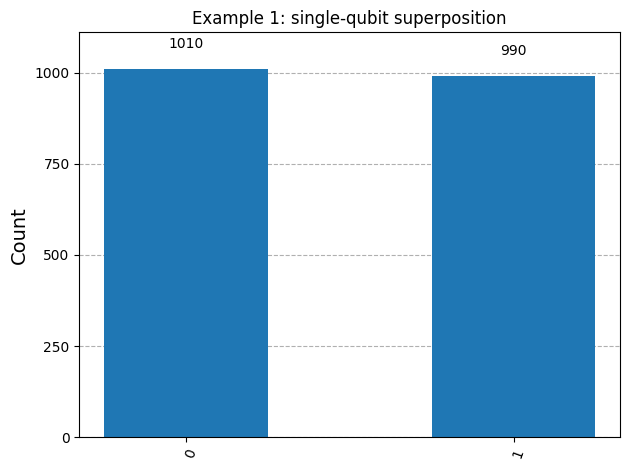

In [16]:
# Example 1: Single-qubit superposition
# H|0> = (|0> + |1>) / sqrt(2)  ->  P(0) = P(1) = 1/2
qc_super = QuantumCircuit(1, 1)
qc_super.h(0)
qc_super.measure(0, 0)

tqc = transpile(qc_super, sim)
result = sim.run(tqc, shots=2000).result()
counts = result.get_counts()
print(counts)
plot_histogram(counts, title="Example 1: single-qubit superposition")


{'11': 968, '00': 1032}


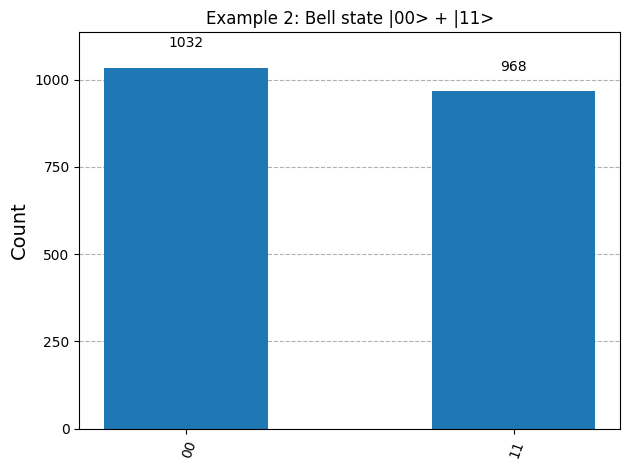

In [17]:
# Example 2: Bell state (entanglement)
# H on q0 creates superposition, CX(q0,q1) entangles -> |Phi+> = (|00> + |11>) / sqrt(2)
qc_bell = QuantumCircuit(2, 2)
qc_bell.h(0)
qc_bell.cx(0, 1)
qc_bell.measure([0, 1], [0, 1])

tqc = transpile(qc_bell, sim)
result = sim.run(tqc, shots=2000).result()
counts = result.get_counts()
print(counts)
# Only '00' and '11' should appear -- q0 and q1 are perfectly correlated
plot_histogram(counts, title="Example 2: Bell state |00> + |11>")


In [18]:
# Example 3: explicit quantum & classical registers, named for readability
qr = QuantumRegister(2, "q")
cr = ClassicalRegister(2, "c")
qc_named = QuantumCircuit(qr, cr)

qc_named.h(qr[0])
qc_named.cx(qr[0], qr[1])
qc_named.measure(qr[0], cr[0])
qc_named.measure(qr[1], cr[1])

print(qc_named.draw())
# Same circuit as Example 2 -- named registers are purely for readability/organization


     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


## 4. Circuit Library: Advanced Architectures

Beyond individual gates, Qiskit ships **structural** circuit-building functions that
generate a whole `QuantumCircuit` from a few parameters: variational ansätze, data-encoding
feature maps, Hamiltonian time evolution, and benchmarking/arithmetic circuits.

> Note: in recent Qiskit, these are lowercase *functions* (`n_local`, `real_amplitudes`,
> `zz_feature_map`, `quantum_volume`) rather than classes -- the class-based versions
> (`NLocal`, `RealAmplitudes`, ...) still work but are deprecated. This notebook uses the
> current function-based API.


In [19]:
# 4a. N-Local circuits: alternate parameterized single-qubit rotations with entangling layers.
# This is the standard building block behind VQE / QAOA-style variational algorithms.
two_local = n_local(3, "rx", "cz")   # 3 qubits: RX rotations + CZ entanglers
print(two_local.draw())
print("\nNumber of free parameters:", two_local.num_parameters)

# Bind every parameter to 0 just to see a concrete circuit
bound = two_local.assign_parameters({p: 0 for p in two_local.parameters})


     ┌──────────┐      ┌──────────┐                  ┌──────────┐            »
q_0: ┤ Rx(θ[0]) ├─■──■─┤ Rx(θ[3]) ├─────────────■──■─┤ Rx(θ[6]) ├────────────»
     ├──────────┤ │  │ └──────────┘┌──────────┐ │  │ └──────────┘┌──────────┐»
q_1: ┤ Rx(θ[1]) ├─■──┼──────■──────┤ Rx(θ[4]) ├─■──┼──────■──────┤ Rx(θ[7]) ├»
     ├──────────┤    │      │      ├──────────┤    │      │      ├──────────┤»
q_2: ┤ Rx(θ[2]) ├────■──────■──────┤ Rx(θ[5]) ├────■──────■──────┤ Rx(θ[8]) ├»
     └──────────┘                  └──────────┘                  └──────────┘»
«           ┌──────────┐             
«q_0: ─■──■─┤ Rx(θ[9]) ├─────────────
«      │  │ └──────────┘┌───────────┐
«q_1: ─■──┼──────■──────┤ Rx(θ[10]) ├
«         │      │      ├───────────┤
«q_2: ────■──────■──────┤ Rx(θ[11]) ├
«                       └───────────┘

Number of free parameters: 12


In [20]:
# 4b. Data-encoding circuits: map classical features into rotation angles + entanglement.
# This is how classical data gets loaded into a quantum feature space for QML.
features = [0.2, 0.4, 0.8]
fmap = zz_feature_map(feature_dimension=len(features))
encoded_qc = fmap.assign_parameters(features)
print(encoded_qc.draw())


   ┌───┐┌────────┐                                              ┌───┐»
0: ┤ H ├┤ P(0.4) ├──■─────────────────■────■─────────────────■──┤ H ├»
   ├───┤├────────┤┌─┴─┐┌───────────┐┌─┴─┐  │                 │  └───┘»
1: ┤ H ├┤ P(0.8) ├┤ X ├┤ P(16.129) ├┤ X ├──┼─────────────────┼────■──»
   ├───┤├────────┤└───┘└───────────┘└───┘┌─┴─┐┌───────────┐┌─┴─┐┌─┴─┐»
2: ┤ H ├┤ P(1.6) ├───────────────────────┤ X ├┤ P(13.776) ├┤ X ├┤ X ├»
   └───┘└────────┘                       └───┘└───────────┘└───┘└───┘»
«     ┌────────┐                                                              »
«0: ──┤ P(0.4) ├───────────────────────■─────────────────■────■───────────────»
«     └────────┘      ┌───┐┌────────┐┌─┴─┐┌───────────┐┌─┴─┐  │               »
«1: ───────────────■──┤ H ├┤ P(0.8) ├┤ X ├┤ P(16.129) ├┤ X ├──┼───────────────»
«   ┌───────────┐┌─┴─┐├───┤├────────┤└───┘└───────────┘└───┘┌─┴─┐┌───────────┐»
«2: ┤ P(12.839) ├┤ X ├┤ H ├┤ P(1.6) ├───────────────────────┤ X ├┤ P(13.776) ├»
«   └───────────┘└───┘└

In [21]:
# 4c. Time-evolution circuits: implement U(t) = exp(-iHt) for a Hamiltonian H.
# Core building block for quantum chemistry simulation and QAOA cost-layer unitaries.
state = QuantumCircuit(3)
state.h(1)

hamiltonian = SparsePauliOp(["ZZI", "IZZ"])   # H = ZZI + IZZ
evolution = PauliEvolutionGate(hamiltonian, time=1)
state.compose(evolution, inplace=True)
print(state.draw())


          ┌──────────────────────────┐
q_0: ─────┤0                         ├
     ┌───┐│                          │
q_1: ┤ H ├┤1 exp(-it (ZZI + IZZ))(1) ├
     └───┘│                          │
q_2: ─────┤2                         ├
          └──────────────────────────┘


In [22]:
# 4d. Benchmarking circuits: Quantum Volume -- random square circuits used to score
# a real device's full-stack performance (gates + connectivity + compilation).
qv = quantum_volume(4)
print(qv.draw(fold=-1))


               ┌──────────┐┌──────────┐            ┌──────────┐┌──────────┐
0: ────────────┤0         ├┤0         ├────────────┤1         ├┤1         ├
   ┌──────────┐│          ││  Unitary │┌──────────┐│          ││  Unitary │
1: ┤1         ├┤  Unitary ├┤1         ├┤1         ├┤          ├┤0         ├
   │          ││          │├──────────┤│  Unitary ││  Unitary │├──────────┤
2: ┤  Unitary ├┤1         ├┤0         ├┤0         ├┤          ├┤1         ├
   │          │└──────────┘│  Unitary │└──────────┘│          ││  Unitary │
3: ┤0         ├────────────┤1         ├────────────┤0         ├┤0         ├
   └──────────┘            └──────────┘            └──────────┘└──────────┘


In [23]:
# 4e. Reversible arithmetic: a ripple-carry adder built entirely from reversible gates.
# Used in amplitude estimation (finance) and linear-system solvers (HHL).
adder = FullAdderGate(3)   # 3-bit in-place adder
print("Adder qubit count:", adder.num_qubits)
print(adder.definition.draw())


Adder qubit count: 8
      ┌──────┐                                     ┌──────┐
 cin: ┤2     ├─────────────────────────────────────┤2     ├
      │      │┌──────┐                     ┌──────┐│      │
 a_0: ┤0     ├┤2     ├─────────────────────┤2     ├┤0     ├
      │      ││      │┌──────┐     ┌──────┐│      ││      │
 a_1: ┤  MAJ ├┤0     ├┤2     ├─────┤2     ├┤0     ├┤  UMA ├
      │      ││      ││      │     │      ││      ││      │
 a_2: ┤      ├┤  MAJ ├┤0     ├──■──┤0     ├┤  UMA ├┤      ├
      │      ││      ││      │  │  │      ││      ││      │
 b_0: ┤1     ├┤      ├┤  MAJ ├──┼──┤  UMA ├┤      ├┤1     ├
      └──────┘│      ││      │  │  │      ││      │└──────┘
 b_1: ────────┤1     ├┤      ├──┼──┤      ├┤1     ├────────
              └──────┘│      │  │  │      │└──────┘        
 b_2: ────────────────┤1     ├──┼──┤1     ├────────────────
                      └──────┘┌─┴─┐└──────┘                
cout: ────────────────────────┤ X ├────────────────────────
                   

## 5. Classical Feedforward & Dynamic Circuits

Dynamic circuits let control hardware **measure mid-circuit and act on the result in
real time**, instead of only measuring at the very end. This is the mechanism behind
active qubit reset, quantum error correction decoding, and constant-depth state
preparation. The key primitives are `qc.if_test(...)`, `qc.switch(...)`, `qc.for_loop(...)`,
and `qc.while_loop(...)`.


In [24]:
# 5a. Active reset pattern: measure a qubit, and if it collapsed to |1>, flip it back to |0>.
qr = QuantumRegister(1, "q")
cr = ClassicalRegister(1, "c")
qc_reset = QuantumCircuit(qr, cr)

qc_reset.h(qr[0])
qc_reset.measure(qr[0], cr[0])

with qc_reset.if_test((cr[0], 1)):   # "if c0 == 1"
    qc_reset.x(qr[0])                # ...deterministically flip back to |0>

qc_reset.measure(qr[0], cr[0])       # read out again to confirm
print(qc_reset.draw())

tqc = transpile(qc_reset, sim)
result = sim.run(tqc, shots=500).result()
print("\nFinal counts (should be ~all '0'):", result.get_counts())


     ┌───┐┌─┐  ┌──────  ┌───┐ ───────┐ ┌─┐
  q: ┤ H ├┤M├──┤ If-0  ─┤ X ├  End-0 ├─┤M├
     └───┘└╥┘  └──╥───  └───┘ ───────┘ └╥┘
           ║ ┌────╨────┐                ║ 
c: 1/══════╩═╡ c_0=0x1 ╞════════════════╩═
           0 └─────────┘                0 

Final counts (should be ~all '0'): {'0': 500}


In [25]:
# 5b. Branching with if_test / else_
qr = QuantumRegister(2, "q")
cr = ClassicalRegister(1, "c")
qc_branch = QuantumCircuit(qr, cr)

qc_branch.h(qr[0])
qc_branch.measure(qr[0], cr[0])

with qc_branch.if_test((cr[0], 1)) as else_:
    qc_branch.h(qr[1])   # if c0 == 1
with else_:
    qc_branch.x(qr[1])   # else

print(qc_branch.draw())


     ┌───┐┌─┐                                         
q_0: ┤ H ├┤M├─────────────────────────────────────────
     └───┘└╥┘  ┌──────  ┌───┐┌──────── ┌───┐ ───────┐ 
q_1: ──────╫───┤ If-0  ─┤ H ├┤ Else-0  ┤ X ├  End-0 ├─
           ║   └──╥───  └───┘└──────── └───┘ ───────┘ 
           ║ ┌────╨────┐                              
c: 1/══════╩═╡ c_0=0x1 ╞══════════════════════════════
           0 └─────────┘                              


In [26]:
# 5c. Multi-way branching with switch -- exactly one matching case executes, no fallthrough
qr = QuantumRegister(3, "q")
cr = ClassicalRegister(3, "c")
qc_switch = QuantumCircuit(qr, cr)

qc_switch.h(qr[0]); qc_switch.h(qr[1]); qc_switch.h(qr[2])
qc_switch.measure(qr[0], cr[0])
qc_switch.measure(qr[1], cr[1])
qc_switch.measure(qr[2], cr[2])

with qc_switch.switch(cr) as case:
    with case(0b000, 0b011):
        qc_switch.z(qr[2])
    with case(0b001):
        qc_switch.y(qr[2])
    with case(case.DEFAULT):
        qc_switch.x(qr[2])

print(qc_switch.draw())


     ┌───┐┌─┐                                                           »
q_0: ┤ H ├┤M├───────────────────────────────────────────────────────────»
     ├───┤└╥┘┌─┐                                                        »
q_1: ┤ H ├─╫─┤M├────────────────────────────────────────────────────────»
     ├───┤ ║ └╥┘┌─┐┌────────── ┌─────────────── ┌───┐┌──────────── ┌───┐»
q_2: ┤ H ├─╫──╫─┤M├┤ Switch-0  ┤ Case-0 (0, 3)  ┤ Z ├┤ Case-0 (1)  ┤ Y ├»
     └───┘ ║  ║ └╥┘└────╥───── └─────────────── └───┘└──────────── └───┘»
           ║  ║  ║   ┌──╨──┐                                            »
c: 3/══════╩══╩══╩═══╡ 0x7 ╞════════════════════════════════════════════»
           0  1  2   └─────┘                                            »
«                                      
«q_0: ─────────────────────────────────
«                                      
«q_1: ─────────────────────────────────
«     ┌──────────────── ┌───┐ ───────┐ 
«q_2: ┤ Case-0 default  ┤ X ├  End-0 ├─
«     └─────────────

In [27]:
# 5d. for_loop: a fixed number of repetitions compiled directly onto the control hardware
qr = QuantumRegister(1, "q")
cr = ClassicalRegister(1, "c")
qc_for = QuantumCircuit(qr, cr)

with qc_for.for_loop(range(5)) as _:
    qc_for.x(qr[0])       # apply X five times in a row -> net effect is identity
qc_for.measure(qr[0], cr[0])

print(qc_for.draw())
tqc = transpile(qc_for, sim)
print("\nCounts (5 X's = identity, expect all '0'):", sim.run(tqc, shots=200).result().get_counts())


     ┌─────────────────── ┌───┐ ───────┐ ┌─┐
  q: ┤ For-0 range(0, 5)  ┤ X ├  End-0 ├─┤M├
     └─────────────────── └───┘ ───────┘ └╥┘
c: 1/═════════════════════════════════════╩═
                                          0 

Counts (5 X's = identity, expect all '0'): {'1': 200}


In [28]:
# 5e. while_loop: repeat-until-success. We FORCE the initial readout to 0b11 (with X gates)
# so the loop is guaranteed to run at least once, then it keeps re-preparing both qubits
# in superposition and re-measuring until the outcome is anything other than '11'.
qr = QuantumRegister(2, "q")
cr = ClassicalRegister(2, "c")
qc_while = QuantumCircuit(qr, cr)

qc_while.x(qr[0]); qc_while.x(qr[1])   # guarantee the first readout is 0b11
qc_while.measure(qr, cr)

with qc_while.while_loop((cr, 0b11)):
    qc_while.h(qr[0]); qc_while.h(qr[1])
    qc_while.measure(qr[0], cr[0])
    qc_while.measure(qr[1], cr[1])

print(qc_while.draw())
tqc = transpile(qc_while, sim)
final_counts = sim.run(tqc, shots=500).result().get_counts()
print("\nFinal counts (0b11 should never appear -- the loop keeps retrying until it's gone):")
print(final_counts)


     ┌───┐┌─┐   ┌───────── ┌───┐┌─┐    ───────┐ 
q_0: ┤ X ├┤M├───┤          ┤ H ├┤M├───        ├─
     ├───┤└╥┘┌─┐│ While-0  ├───┤└╥┘┌─┐  End-0 │ 
q_1: ┤ X ├─╫─┤M├┤          ┤ H ├─╫─┤M├        ├─
     └───┘ ║ └╥┘└────╥──── └───┘ ║ └╥┘ ───────┘ 
           ║  ║   ┌──╨──┐        ║  ║           
c: 2/══════╩══╩═══╡ 0x3 ╞════════╩══╩═══════════
           0  1   └─────┘        0  1           

Final counts (0b11 should never appear -- the loop keeps retrying until it's gone):
{'01': 168, '00': 158, '10': 174}


In [29]:
# 5f. Classical expressions (expr) & store: real-time classical math on measured bits,
# e.g. computing a parity bit from a classical register.
qr = QuantumRegister(4, "q")
creg = ClassicalRegister(3, "creg")
qc_expr = QuantumCircuit(qr, creg)

qc_expr.h(qr[0]); qc_expr.h(qr[1]); qc_expr.h(qr[2])
qc_expr.measure(qr[0], creg[0])
qc_expr.measure(qr[1], creg[1])
qc_expr.measure(qr[2], creg[2])

# Declare a classical variable ("Var") to store an intermediate expression result in
temp = qc_expr.add_var("temp", expr.lift(creg))
qc_expr.store(temp, expr.bit_not(creg))       # temp = NOT(creg), evaluated bitwise/in parallel

parity = expr.bit_xor(
    expr.bit_xor(expr.index(temp, 0), expr.index(temp, 1)),
    expr.index(temp, 2),
)
with qc_expr.if_test(parity):
    qc_expr.x(qr[3])   # flip q3 only if the parity of NOT(creg) is 1

print(qc_expr.draw())


        ┌───┐┌─┐                                                         
   q_0: ┤ H ├┤M├─────────────────────────────────────────────────────────
        ├───┤└╥┘┌─┐                                                      
   q_1: ┤ H ├─╫─┤M├──────────────────────────────────────────────────────
        ├───┤ ║ └╥┘┌─┐                                                   
   q_2: ┤ H ├─╫──╫─┤M├───────────────────────────────────────────────────
        └───┘ ║  ║ └╥┘┌────────────────────────────────── ┌───┐ ───────┐ 
   q_3: ──────╫──╫──╫─┤ If-0 temp[0] ^ temp[1] ^ temp[2]  ┤ X ├  End-0 ├─
              ║  ║  ║ └────────────────────────────────── └───┘ ───────┘ 
creg: 3/══════╩══╩══╩════════════════════════════════════════════════════
              0  1  2                                                    


### Case study: long-range entanglement via a dynamic circuit

The slides describe constant-depth GHZ preparation: instead of a linear chain of CNOTs
(depth grows with qubit count), you build small local Bell pairs, **fuse** them together
with a mid-circuit Bell-basis measurement, and use classical feedforward to correct for the
random measurement outcome. The result is long-range entanglement between qubits that were
never directly coupled by a two-qubit gate.

Below is a small, fully-verified version of that idea: **entanglement swapping**. `q0` and
`q3` never interact directly, yet after the fusion + correction they come out perfectly
correlated.


In [30]:
qr = QuantumRegister(4, "q")
cr = ClassicalRegister(4, "c")   # c0,c1 = fusion (Bell) measurement; c2,c3 = final readout
qc_swap = QuantumCircuit(qr, cr)

# Two independent, LOCAL Bell pairs -- (q0,q1) and (q2,q3) never touch each other yet
qc_swap.h(qr[0]); qc_swap.cx(qr[0], qr[1])
qc_swap.h(qr[2]); qc_swap.cx(qr[2], qr[3])

# Bell-basis measurement that FUSES q1 and q2
qc_swap.cx(qr[1], qr[2])
qc_swap.h(qr[1])
qc_swap.measure(qr[1], cr[0])
qc_swap.measure(qr[2], cr[1])

# Classical feedforward correction on the two SURVIVING qubits, q0 and q3
with qc_swap.if_test((cr[1], 1)):
    qc_swap.x(qr[3])
with qc_swap.if_test((cr[0], 1)):
    qc_swap.z(qr[0])

# Read out the (now long-range) entanglement between q0 and q3
qc_swap.measure(qr[0], cr[2])
qc_swap.measure(qr[3], cr[3])

print(qc_swap.draw())

tqc = transpile(qc_swap, sim)
counts = sim.run(tqc, shots=2000).result().get_counts()

# Aggregate over just the final readout bits (c3 c2), ignoring the fusion outcome (c1 c0)
from collections import Counter
final_only = Counter()
for bitstring, n in counts.items():
    final_only[bitstring[:2]] += n   # Qiskit orders bitstrings c3c2c1c0 (MSB first)

print("\nFinal readout of (q3, q0) -- only '00' and '11' should appear:")
print(dict(final_only))


     ┌───┐                                              ┌──────  ┌───┐ ───────┐»
q_0: ┤ H ├──■───────────────────────────────────────────┤ If-0  ─┤ Z ├  End-0 ├»
     └───┘┌─┴─┐     ┌───┐┌─┐                            └──╥───  └───┘ ───────┘»
q_1: ─────┤ X ├──■──┤ H ├┤M├───────────────────────────────╫───────────────────»
     ┌───┐└───┘┌─┴─┐└┬─┬┘└╥┘                               ║                   »
q_2: ┤ H ├──■──┤ X ├─┤M├──╫────────────────────────────────╫───────────────────»
     └───┘┌─┴─┐└───┘ └╥┘  ║   ┌──────  ┌───┐ ───────┐      ║                   »
q_3: ─────┤ X ├───────╫───╫───┤ If-0  ─┤ X ├  End-0 ├──────╫───────────────────»
          └───┘       ║   ║   └──╥───  └───┘ ───────┘      ║                   »
                      ║   ║ ┌────╨────┐               ┌────╨────┐              »
c: 4/═════════════════╩═══╩═╡ c_1=0x1 ╞═══════════════╡ c_0=0x1 ╞══════════════»
                      1   0 └─────────┘               └─────────┘              »
«         ┌─┐
«q_0: ────┤M├


## 6. Parameterized Quantum Circuits

A `Parameter` is a symbolic placeholder for a gate argument. You build and transpile the
circuit **once**, then bind concrete numeric values on the fly -- this is the backbone of
VQE, QAOA, and quantum neural networks, where the same circuit structure is evaluated for
many different angle values inside a classical optimization loop.


In [31]:
# 6a. Declaring and drawing a symbolic parameter
theta = Parameter("theta")
qc_param = QuantumCircuit(1)
qc_param.rx(theta, 0)
print(qc_param.draw())
print("\nUnbound parameters:", qc_param.parameters)


   ┌───────────┐
q: ┤ Rx(theta) ├
   └───────────┘

Unbound parameters: ParameterView([Parameter(theta)])


In [32]:
# 6b. Binding parameters three ways: single value, in-place, and a full sweep
# 1. Single numeric value (returns a NEW bound copy)
bound_qc = qc_param.assign_parameters({theta: np.pi / 2})
print(bound_qc.draw())

# 2. In-place assignment (mutates a copy -- be careful re-running this cell on qc_param itself!)
qc_inplace = qc_param.copy()
qc_inplace.assign_parameters({theta: np.pi / 4}, inplace=True)

# 3. Parameter sweep across an interval -- one bound circuit per angle
angles = np.linspace(0, 2 * np.pi, 50)
circuits = [qc_param.assign_parameters({theta: val}) for val in angles]
print(f"\nBuilt {len(circuits)} bound circuits from one parameterized template.")


   ┌─────────┐
q: ┤ Rx(π/2) ├
   └─────────┘

Built 50 bound circuits from one parameterized template.


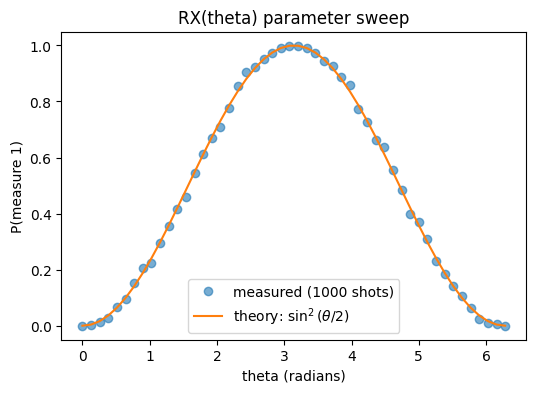

In [33]:
# 6c. Put the sweep to work: measure P(1) vs theta for RX(theta) and check it against
# the textbook formula P(1) = sin^2(theta / 2).
qc_sweep = QuantumCircuit(1, 1)
qc_sweep.rx(theta, 0)
qc_sweep.measure(0, 0)

p1_measured = []
for val in angles:
    bound = qc_sweep.assign_parameters({theta: val})
    tqc = transpile(bound, sim)
    counts = sim.run(tqc, shots=1000).result().get_counts()
    p1_measured.append(counts.get("1", 0) / 1000)

p1_theory = np.sin(angles / 2) ** 2

plt.figure(figsize=(6, 4))
plt.plot(angles, p1_measured, "o", label="measured (1000 shots)", alpha=0.6)
plt.plot(angles, p1_theory, "-", label=r"theory: $\sin^2(\theta/2)$")
plt.xlabel("theta (radians)")
plt.ylabel("P(measure 1)")
plt.title("RX(theta) parameter sweep")
plt.legend()
plt.show()


In [34]:
# 6d. ParameterVector: scale to many parameters (e.g. one per qubit per layer) without
# declaring individual Parameter objects, plus symbolic arithmetic on gate angles.
theta_vec = ParameterVector("theta", length=3)
qc_vec = QuantumCircuit(3)
for i in range(3):
    qc_vec.ry(theta_vec[i], i)

phi = Parameter("phi")
qc_vec.rz(2 * phi + np.pi / 4, 0)   # affine transform of a parameter directly in the gate angle

print(qc_vec.draw())
print("\nAll free parameters:", list(qc_vec.parameters))


     ┌──────────────┐┌─────────────────┐
q_0: ┤ Ry(theta[0]) ├┤ Rz(π/4 + 2*phi) ├
     ├──────────────┤└─────────────────┘
q_1: ┤ Ry(theta[1]) ├───────────────────
     ├──────────────┤                   
q_2: ┤ Ry(theta[2]) ├───────────────────
     └──────────────┘                   

All free parameters: [Parameter(phi), ParameterVectorElement(theta[0]), ParameterVectorElement(theta[1]), ParameterVectorElement(theta[2])]


In [35]:
# 6e. Case study: a variational ansatz (RealAmplitudes) -- the standard VQE building block.
# Bind it to random angles and look at the resulting statevector / measurement distribution.
ansatz = real_amplitudes(num_qubits=2, reps=1)
print(ansatz.draw())

rng = np.random.default_rng(42)
random_angles = {p: rng.uniform(0, 2 * np.pi) for p in ansatz.parameters}
bound_ansatz = ansatz.assign_parameters(random_angles)

sv = Statevector(bound_ansatz)
print("\nResulting statevector:", sv)
print("Probabilities:", sv.probabilities_dict())


     ┌──────────┐     ┌──────────┐
q_0: ┤ Ry(θ[0]) ├──■──┤ Ry(θ[2]) ├
     ├──────────┤┌─┴─┐├──────────┤
q_1: ┤ Ry(θ[1]) ├┤ X ├┤ Ry(θ[3]) ├
     └──────────┘└───┘└──────────┘

Resulting statevector: Statevector([-0.41957977+0.j,  0.72367657+0.j, -0.47695718+0.j,
             -0.26973486+0.j],
            dims=(2, 2))
Probabilities: {np.str_('00'): np.float64(0.176047181757303), np.str_('01'): np.float64(0.5237077732930612), np.str_('10'): np.float64(0.22748815063119987), np.str_('11'): np.float64(0.07275689431843585)}


## 7. Transpile and Optimize Circuits

Some operations (like `MCXGate`) are **abstract** -- there are multiple valid hardware
decompositions, and the transpiler picks one based on the target basis gates, connectivity,
and optimization level. Let's transpile the same circuit at different optimization levels
and compare depth and gate counts -- exactly the trade-off a real backend submission has
to navigate.


In [36]:
qc_deep = QuantumCircuit(4)
qc_deep.h(0)
qc_deep.append(MCXGate(3), [0, 1, 2, 3])

print("Original -- depth:", qc_deep.depth(), " gate counts:", dict(qc_deep.count_ops()))

for level in [0, 1, 2, 3]:
    t = transpile(qc_deep, basis_gates=["u", "cx"], optimization_level=level)
    print(f"opt_level={level} -- depth: {t.depth():3d}   gate counts: {dict(t.count_ops())}")


Original -- depth: 2  gate counts: {'h': 1, 'mcx': 1}
opt_level=0 -- depth:  28   gate counts: {'u': 18, 'cx': 14}
opt_level=1 -- depth:  27   gate counts: {'u': 16, 'cx': 14}
opt_level=2 -- depth:  27   gate counts: {'u': 16, 'cx': 14}
opt_level=3 -- depth:  27   gate counts: {'u': 16, 'cx': 14}


## Wrap-up

You've now touched every code pattern from the deck, live:

- Building & measuring circuits, and verifying unitarity directly
- The standard gate library and `Gate` object methods (`to_matrix`, `power`, `control`)
- Structural circuits: `n_local`, feature maps, Hamiltonian time evolution, `quantum_volume`,
  reversible arithmetic
- Dynamic circuits: `if_test`, `switch`, `for_loop`, `while_loop`, `expr`/`store`, and a
  working long-range-entanglement case study
- Parameterized circuits: binding, sweeping, `ParameterVector`, and a variational ansatz
- Transpilation trade-offs across optimization levels

**For the certification exam specifically:** make sure you can do all of the above *without*
looking anything up — know the difference between `measure_all()` and explicit
`measure()`, know that `if_test`/`switch`/loops need classical registers, and know which
circuit-library functions are the current (lowercase, function-based) API vs. the
deprecated class-based ones (e.g. `real_amplitudes` vs. `RealAmplitudes`).


